# [GSE120376](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE120376)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-10-20
> - Modified: 2024-12-07

# 1. Experimental Design

> Genome-wide histone modification and accessibility maps of mESCs, in the pluripotent state and after induced differentiation
> - Ramisch, A., Heinrich, V., Glaser, L.V. et al. CRUP: a comprehensive framework to predict condition-specific regulatory units. Genome Biol 20, 227 (2019). https://doi.org/10.1186/s13059-019-1860-7.
> - Illumina HiSeq 2500, PE50
> - ChIP-seq
> - ATAC-seq

| Sample | Organism | Cell | Source | Strain | Treatment |
| - | - | - | - | - | - |
| LIF | Mus musculus | mESC | Embryionic stem cell | E14 | Leukemia inhibitory factor (LIF) |
| RA | Mus musculus | mESC | Embryionic stem cell | E14 | Retinoic acid (RA) |

> Note:
> - E14 mouse embryonic stem cells (mESCs) were cultured and routinely passaged every 2 days in ES medium plus leukemia inhibitory factor (LIF) in order to maintain the pluripotent state of the cells. To exit from pluripotency and push the cells towards differentiation, LIF was withdrawn and retinoic acid (RA) was added to the medium for a short pulse of 4 h.

| Marks | Peak shape | Function | Chromatin Status |
| - | - | - | - |
| H3K4me1 | Sharp / Moderate | Enhancer | Activation |
| H3K4me3 | Sharp | Promoter | Activation |
| H3K27ac | Sharp / Moderate | Promoter (H3K4me3) and Enhancer (H3K4me1) | Activation |
| H3K122ac | Sharp | Chromatin | Activation |
| H3K36me3 | Broad | Gene body (3') | Elongation |
| H3K79me2 | Broad | Gene body (5') | Elongation |
| H3K27me3 | Broad | Bivalent domain | Repression (Polycomb) |
| H3K9me3 | Very broad | Heterochromatin / Repeat | Repression |
| ATAC | Sharp | - | Activation |

In [ ]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376"
atacseq_dir <- file.path(data_dir, "04_atacseq_output")
chipseq_dir <- file.path(data_dir, "06_chipseq_output")

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

# 2. Evaluate Library Quality

See more: [NGS13_ChIPseq_01_HistonesPattern_GSE120376](NGS13_ChIPseq_01_HistonesPattern_GSE120376.ipynb)

# 3. Import Data

In [3]:
treatment <- c("LIF", "RA")

marks <- c(
    "H3K4me3", "H3K4me1", "H3K27ac", "H3K122ac", 
    "H3K79me2", "H3K36me3", "H3K27me3", "H3K9me3")

broad_marks <- c("H3K36me3", "H3K79me2", "H3K27me3", "H3K9me3")

sample_order <- expand.grid(treatment, c("ATAC", marks, "Input")) |> 
    {\(x) paste(x$Var1, x$Var2, sep = "_")}()

sample_order

[1] "LIF_ATAC"     "RA_ATAC"      "LIF_H3K4me3"  "RA_H3K4me3"   "LIF_H3K4me1" 
 [6] "RA_H3K4me1"   "LIF_H3K27ac"  "RA_H3K27ac"   "LIF_H3K122ac" "RA_H3K122ac" 
[11] "LIF_H3K79me2" "RA_H3K79me2"  "LIF_H3K36me3" "RA_H3K36me3"  "LIF_H3K27me3"
[16] "RA_H3K27me3"  "LIF_H3K9me3"  "RA_H3K9me3"   "LIF_Input"    "RA_Input"

## 1). Import narrowPeak

In [ ]:
# Load macs2 narrowPeak file as GRanges
load_narrowPeak <- function(
    file, format = "auto", keepStandardChr = TRUE, 
    dropSex = TRUE, dropMito = TRUE, blacklist = NULL) {

    if (format == "auto") {
        if (grepl("\\.narrowPeak$", file)) {
            format <- "narrowPeak"
        } else if (grepl("\\.broadPeak$", file)) {
            format <- "broadPeak"
        } else if (grepl("\\.gappedPeak$", file)) {
            format <- "gappedPeak"
        } else {
            format <- "BED"
        }
    }

    gr <- rtracklayer::import(file, format = format)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist region (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [5]:
atac_peaks_files <- file.path(atacseq_dir, "05_peaks") |>
    list.files(pattern = "peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

In [6]:
chip_peaks_files <- marks |> 
    map(\(mark) {
        if (mark %in% broad_marks) {
            folder <- "05_peaks_broad"
            pattern <- paste0("_", mark, "_peaks\\.broadPeak$")
        } else {
            folder <- "05_peaks"
            pattern <- paste0("_", mark, "_peaks\\.narrowPeak$")
        }

        full_path <- file.path(chipseq_dir, folder) |>
            list.files(pattern = pattern, full.names = TRUE)
        
        return(full_path)}) |> flatten_chr()

names(chip_peaks_files) <- chip_peaks_files |> basename() |> 
    sub("_peaks\\.(narrowPeak|broadPeak)$", "", x = _)

# chip_peaks_files <- file.path(chipseq_dir, "05_peaks") |>
#     list.files(pattern = "peaks\\.narrowPeak$") |>
#     set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", .x))

In [7]:
peaks_files <- c(atac_peaks_files, chip_peaks_files)
names(peaks_files) <- sub("^[^_]+_", "", names(peaks_files))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> cat(sep = "\n")

LIF_ATAC: mESC_LIF_ATAC_peaks.narrowPeak
RA_ATAC: mESC_RA_ATAC_peaks.narrowPeak
LIF_H3K4me3: mESC_LIF_H3K4me3_peaks.narrowPeak
RA_H3K4me3: mESC_RA_H3K4me3_peaks.narrowPeak
LIF_H3K4me1: mESC_LIF_H3K4me1_peaks.narrowPeak
RA_H3K4me1: mESC_RA_H3K4me1_peaks.narrowPeak
LIF_H3K27ac: mESC_LIF_H3K27ac_peaks.narrowPeak
RA_H3K27ac: mESC_RA_H3K27ac_peaks.narrowPeak
LIF_H3K122ac: mESC_LIF_H3K122ac_peaks.narrowPeak
RA_H3K122ac: mESC_RA_H3K122ac_peaks.narrowPeak
LIF_H3K79me2: mESC_LIF_H3K79me2_peaks.broadPeak
RA_H3K79me2: mESC_RA_H3K79me2_peaks.broadPeak
LIF_H3K36me3: mESC_LIF_H3K36me3_peaks.broadPeak
RA_H3K36me3: mESC_RA_H3K36me3_peaks.broadPeak
LIF_H3K27me3: mESC_LIF_H3K27me3_peaks.broadPeak
RA_H3K27me3: mESC_RA_H3K27me3_peaks.broadPeak
LIF_H3K9me3: mESC_LIF_H3K9me3_peaks.broadPeak
RA_H3K9me3: mESC_RA_H3K9me3_peaks.broadPeak


In [ ]:
peaks_list <- lapply(
    peaks_files, load_narrowPeak, dropSex = FALSE, blacklist = blacklist_file)
peaks_list <- peaks_list[sample_order[seq_len(length(sample_order) - 2)]]

## 2). Import bigwig

In [ ]:
# Load bigwig (bw) file as GRanges
load_bigwig <- function(
    file, keepStandardChr = TRUE, 
    dropSex = TRUE, dropMito = TRUE, blacklist = NULL) {

    gr <- rtracklayer::import.bw(file)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist regions (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }        
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [ ]:
atac_signals_files <- file.path(atacseq_dir, "07_bigwig") |>
    list.files(pattern = "\\.bin10.bw$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bin10.bw$", "\\1", basename(.x))) |>
    (\(files) files[!grepl("shifted", files)])()

chip_signals_files <- file.path(chipseq_dir, "07_bigwig") |>
    list.files(pattern = "\\.bin10.bw$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bin10.bw$", "\\1", basename(.x)))

signals_files <- c(atac_signals_files, chip_signals_files)
names(signals_files) <- sub("^[^_]+_", "", names(signals_files))

paste(names(signals_files), basename(signals_files), sep = ": ") |> 
    cat(sep = "\n")

LIF_ATAC: mESC_LIF_ATAC.bin10.bw
RA_ATAC: mESC_RA_ATAC.bin10.bw
LIF_H3K122ac: mESC_LIF_H3K122ac.bin10.bw
LIF_H3K27ac: mESC_LIF_H3K27ac.bin10.bw
LIF_H3K27me3: mESC_LIF_H3K27me3.bin10.bw
LIF_H3K36me3: mESC_LIF_H3K36me3.bin10.bw
LIF_H3K4me1: mESC_LIF_H3K4me1.bin10.bw
LIF_H3K4me3: mESC_LIF_H3K4me3.bin10.bw
LIF_H3K79me2: mESC_LIF_H3K79me2.bin10.bw
LIF_H3K9me3: mESC_LIF_H3K9me3.bin10.bw
LIF_Input: mESC_LIF_Input.bin10.bw
RA_H3K122ac: mESC_RA_H3K122ac.bin10.bw
RA_H3K27ac: mESC_RA_H3K27ac.bin10.bw
RA_H3K27me3: mESC_RA_H3K27me3.bin10.bw
RA_H3K36me3: mESC_RA_H3K36me3.bin10.bw
RA_H3K4me1: mESC_RA_H3K4me1.bin10.bw
RA_H3K4me3: mESC_RA_H3K4me3.bin10.bw
RA_H3K79me2: mESC_RA_H3K79me2.bin10.bw
RA_H3K9me3: mESC_RA_H3K9me3.bin10.bw
RA_Input: mESC_RA_Input.bin10.bw


In [ ]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file)
signals_list <- signals_list[sample_order]

# 4. Histons Pattern

## 1). Number of Peaks

In [12]:
coldata <- tibble(sample = names(peaks_list)) |>
    separate(
        sample, into = c("Treatment", "Marks"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = "mESC", 
        Treatment = factor(Treatment, levels = c("LIF", "RA")),
        Marks = factor(Marks, levels = c("ATAC", marks)),
        Number = lengths(peaks_list)) |>
    arrange(Marks, Treatment) |> 
    column_to_rownames("sample")

coldata

,Treatment,Marks,Cell,Number
,<fct>,<fct>,<chr>,<int>
LIF_ATAC,LIF,ATAC,mESC,109058
RA_ATAC,RA,ATAC,mESC,96373
LIF_H3K4me3,LIF,H3K4me3,mESC,43494
RA_H3K4me3,RA,H3K4me3,mESC,37321
LIF_H3K4me1,LIF,H3K4me1,mESC,131355
RA_H3K4me1,RA,H3K4me1,mESC,116377
LIF_H3K27ac,LIF,H3K27ac,mESC,44684
RA_H3K27ac,RA,H3K27ac,mESC,48494
LIF_H3K122ac,LIF,H3K122ac,mESC,85005


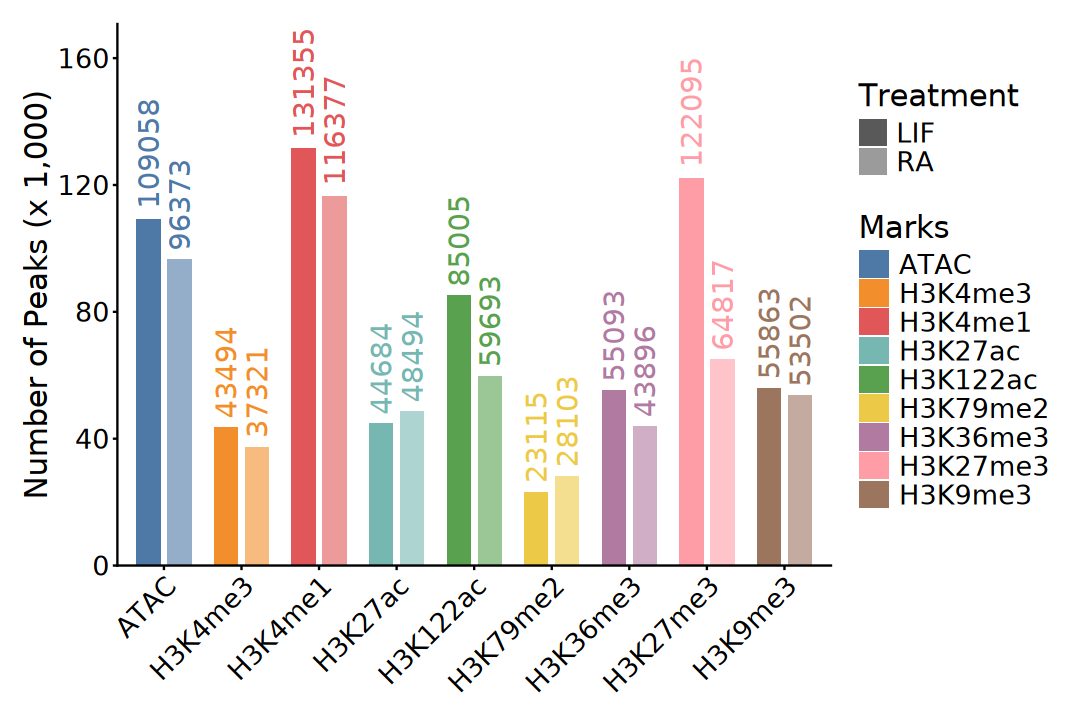

In [13]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(coldata, aes(Marks, Number)) +
    geom_bar(
        aes(fill = Marks, alpha = Treatment, group = Treatment), 
        position = position_dodge(width = 0.8), 
        stat = "identity", width = 0.6) +
    geom_text(
        aes(color = Marks, group = Treatment, label = Number), 
        position = position_dodge(width = 0.8),
        angle = 90, hjust = -0.1, vjust = 0.5, size = 6) +
    scale_y_continuous(
        labels = function(x) x / 1000, 
        expand = expansion(mult = c(0, 0.3))) + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    ggthemes::scale_fill_tableau(palette = "Tableau 10") + 
    scale_alpha_manual(values = c("LIF" = 1.0, "RA" = 0.6)) +
    labs(x = NULL, y = "Number of Peaks (x 1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
        axis.text.y = element_text(size = 16))

## 2). Peaks Annotation

In [14]:
# load reference gene anntotion
gtf <- import(gtf_file) |> 
    BRGenomics::tidyChromosomes(
        keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

standard_chromosome <- seqinfo(gtf) |> seqnames()

In [15]:
# txdb <- txdbmaker::makeTxDbFromGFF(
#     gtf_file, dataSource = "Gencode", 
#     organism = "Mus musculus", taxonomyId = 10090, 
#     metadata = data.frame(
#         name = c("Genome", "Gencode Release"), 
#         value = c("mm10", "vM23")))

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


In [16]:
blacklist <- rtracklayer::import(blacklist_file)
blacklist

GRanges object with 3435 ranges and 1 metadata column:
         seqnames            ranges strand |               name
            <Rle>         <IRanges>  <Rle> |        <character>
     [1]    chr10         1-3135400      * | High Signal Region
     [2]    chr10   3218901-3276600      * |    Low Mappability
     [3]    chr10   3576901-3627700      * |    Low Mappability
     [4]    chr10   4191101-4197600      * |    Low Mappability
     [5]    chr10   4613501-4615400      * | High Signal Region
     ...      ...               ...    ... .                ...
  [3431]     chrY   6530201-6663200      * | High Signal Region
  [3432]     chrY   6760201-6835800      * | High Signal Region
  [3433]     chrY   6984101-8985400      * | High Signal Region
  [3434]     chrY 10638501-41003800      * | High Signal Region
  [3435]     chrY 41159201-91744600      * | High Signal Region
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths

### a). ChIPseeker

In [17]:
suppressPackageStartupMessages(library(ChIPseeker))

In [18]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "gene", verbose = FALSE,
    genomicAnnotationPriority = c(
        "Promoter", "Exon", "Intron", "Intergenic"))

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Gen

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>.”


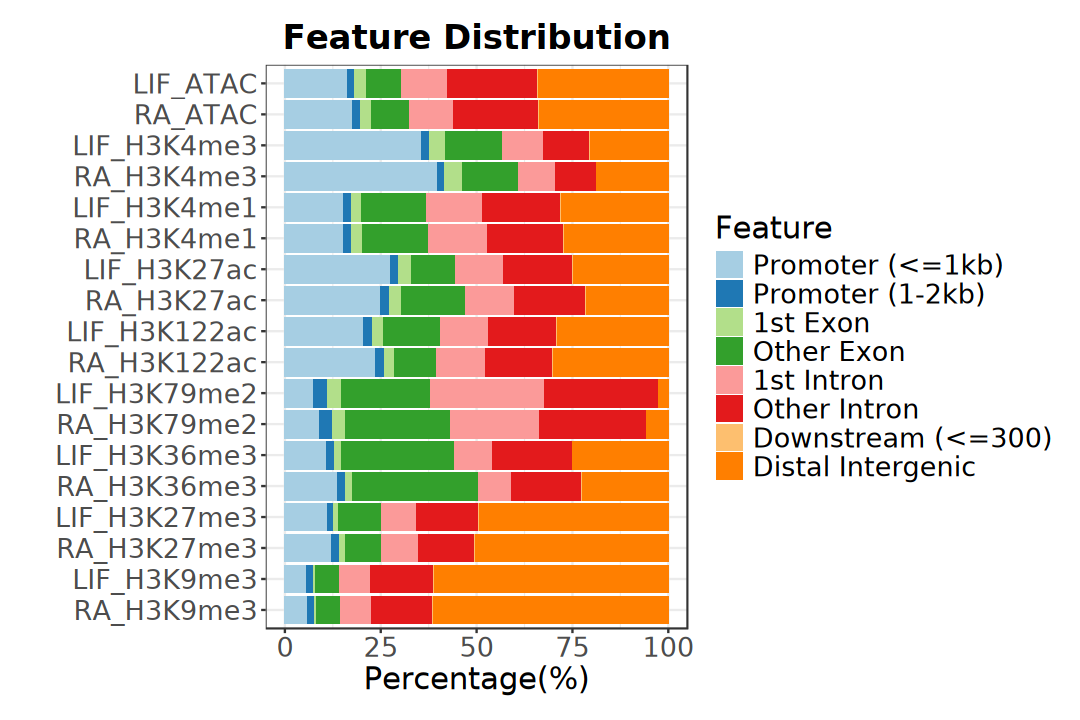

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

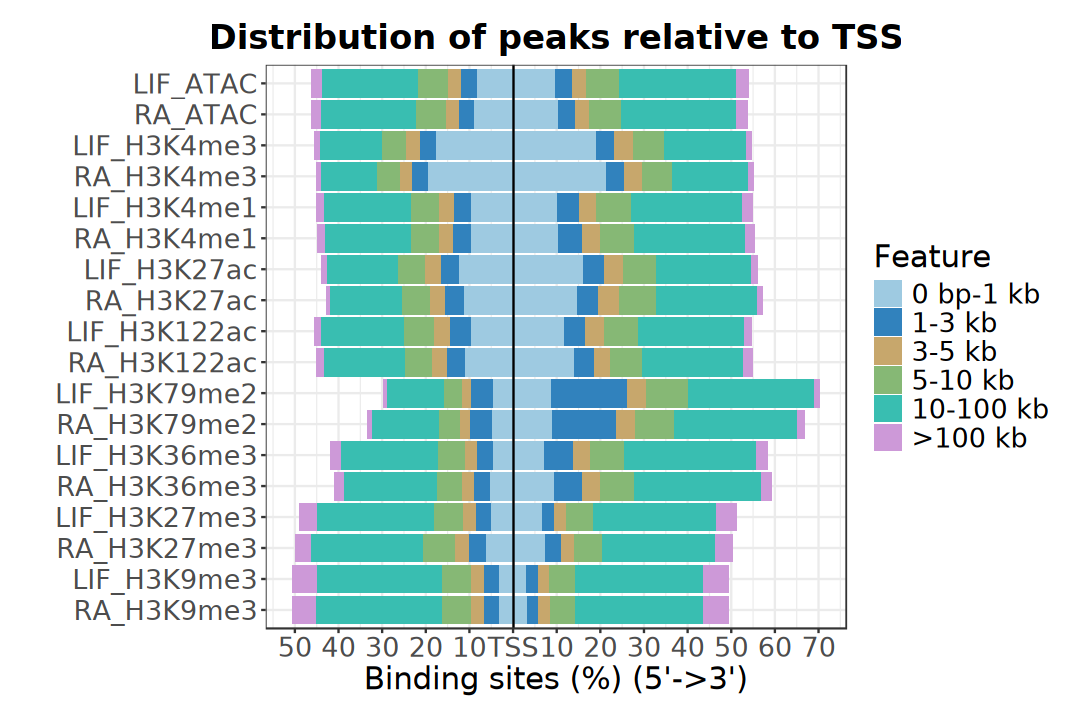

In [20]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDistToTSS(peaks_anno_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [21]:
anno_stats <- lapply(peaks_anno_list, function(anno) {
    anno@annoStat |> 
    mutate(
        MergedFeature = case_when(
            Feature %in% c(
                "Promoter (<=1kb)", "Promoter (1-2kb)") ~ "Promoter",
            Feature %in% c(
                "1st Exon", "Other Exon") ~ "Exon",
            Feature %in% c(
                "1st Intron", "Other Intron") ~ "Intron",
            Feature %in% c(
                "Downstream (<=300)", "Distal Intergenic") ~ "Intergenic",
            TRUE ~ as.character(Feature))) |>
    group_by(MergedFeature) |> 
    summarise(Frequency = sum(Frequency)) |>
    ungroup()
})

In [22]:
anno_stats_combined <- bind_rows(anno_stats, .id = "Sample") |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

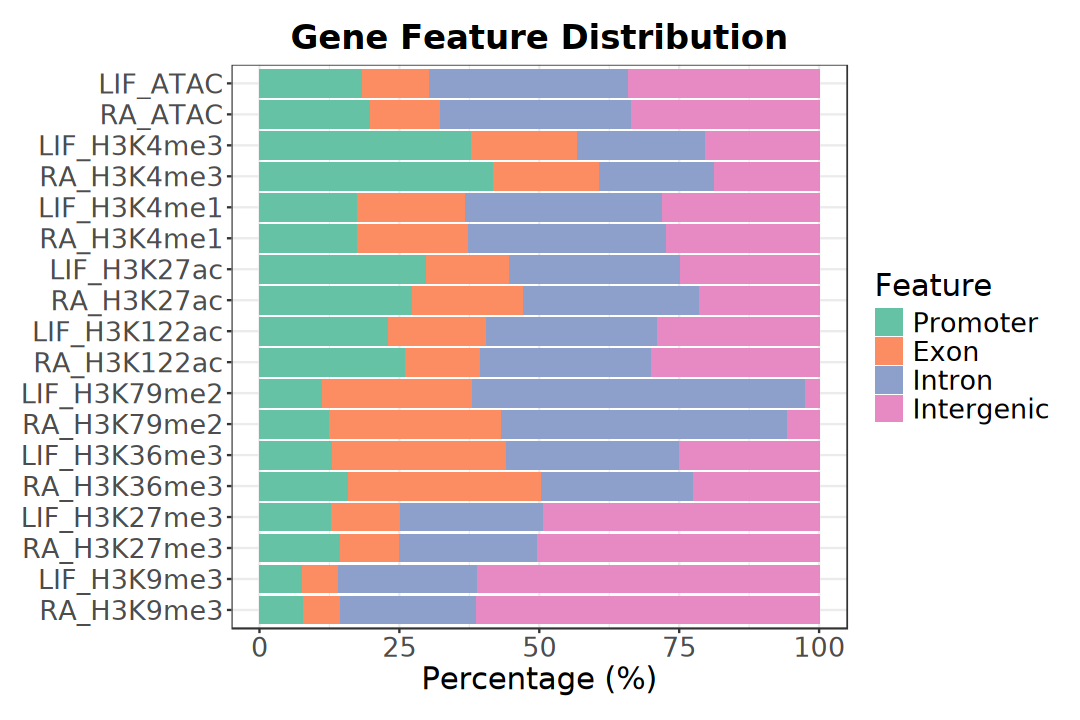

In [23]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). ChIPpeakAnno

In [24]:
suppressPackageStartupMessages(library(ChIPpeakAnno))

In [25]:
peaks_anno_list <- lapply(
    peaks_list, assignChromosomeRegion, 
    TxDb = txdb, nucleotideLevel = FALSE,
    proximal.promoter.cutoff = c(upstream = 2000, downstream = 500),
    immediate.downstream.cutoff = c(upstream = 0, downstream = 0),
    precedence = c(
        "Promoters", "fiveUTRs", "threeUTRs", "Exons", 
        "Introns", "immediateDownstream"))

In [26]:
anno_stats <- lapply(peaks_anno_list, function(anno) {
    anno$percentage |> 
        as.data.frame() |>
        rownames_to_column(var = "Feature") |>
        mutate(
            MergedFeature = case_when(
                Feature %in% c(
                    "Promoters") ~ "Promoter",
                Feature %in% c(
                    "Exons", "fiveUTRs", "threeUTRs") ~ "Exon",
                Feature %in% c(
                    "Introns") ~ "Intron",
                Feature %in% c(
                    "immediateDownstream", "Intergenic.Region") ~ "Intergenic",
                TRUE ~ as.character(Feature))) |>
        group_by(MergedFeature) |> 
        summarise(Frequency = sum(`anno$percentage`)) |>
        ungroup()
})

In [27]:
anno_stats_combined <- bind_rows(anno_stats, .id = "Sample") |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

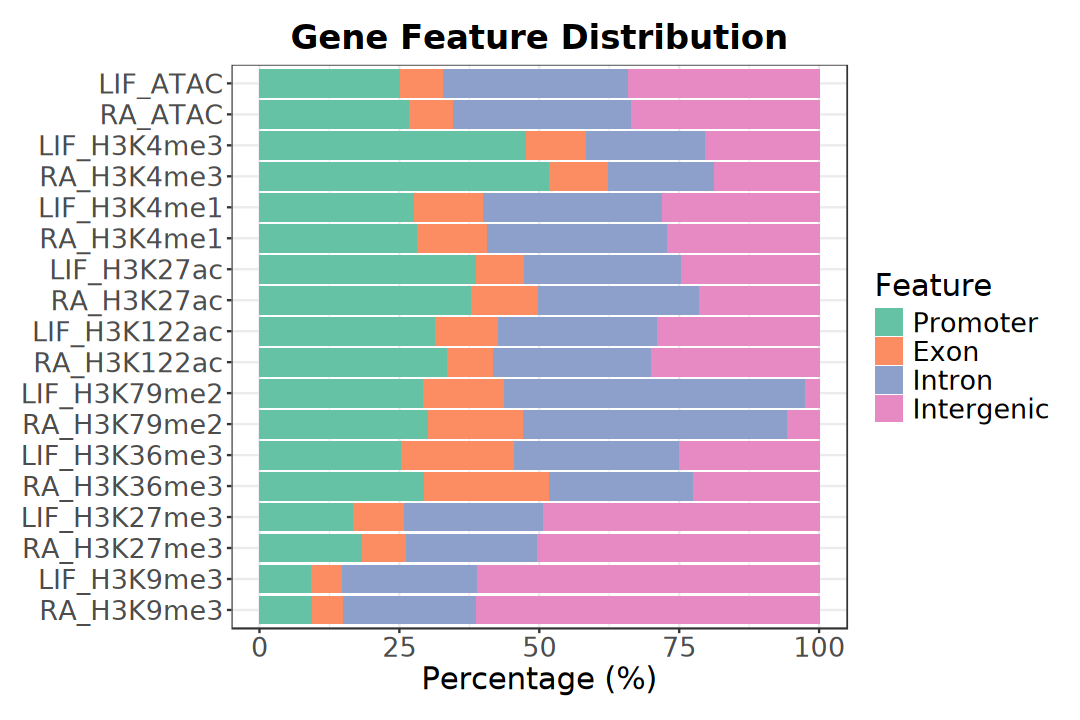

In [28]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### c). Manual

In [29]:
feature_list <- list(
    TSS = gtf[gtf$type == "gene", ] |> 
        promoters(upstream = 0, downstream = 1),
    Promoter = gtf[gtf$type == "gene", ] |>
        promoters(upstream = 2000, downstream = 500),
    Exon = gtf[gtf$type == "exon", ],
    Intron = GenomicFeatures::intronsByTranscript(
        txdb, use.names = TRUE) |> 
        unlist()
)

In [30]:
# ------------------------------------------------------------------------------
# Function: annotate_peaks_with_genomic_features
#
# Description:
# This function performs hierarchical genomic annotation of peak regions 
# (GRanges) based on predefined genomic feature categories and computes the 
# strand-aware signed distance to the nearest transcription start site (TSS).
# ------------------------------------------------------------------------------

annotate_peaks_with_genomic_features <- function(
    peaks, featureList, sameStrand = FALSE, 
    precedence = c("Promoter", "Exon", "Intron", "Intergenic")) {

    peaks$Annotation <- "Intergenic"
    precedence <- precedence[precedence != "Intergenic"]

    for (feature in rev(precedence)) {
        if (!feature %in% names(featureList)) next
        hits <- overlapsAny(
            peaks, featureList[[feature]], ignore.strand = !sameStrand)
        peaks$Annotation[hits] <- feature
    }
    
    idx <- nearest(
        peaks, featureList[["TSS"]], ignore.strand = !sameStrand)

    peak_center <- start(peaks) + 
        ifelse(
            "peak" %in% colnames(mcols(peaks)), 
            peaks$peak, round(width(peaks)/2))

    tss_coord <- start(featureList[["TSS"]])[idx]
    tss_str <- as.vector(strand(featureList[["TSS"]]))[idx]

    dist <- peak_center - tss_coord
    dist[tss_str == "-"] <- -dist[tss_str == "-"]
    dist[is.na(idx)] <- NA_integer_

    peaks$SignedDistToTSS <- dist

    return(peaks)
}

In [31]:
peaks_anno_list <- lapply(
    peaks_list, annotate_peaks_with_genomic_features, 
    featureList = feature_list)

In [32]:
anno_stats <- imap_dfr(peaks_anno_list, function(gr, sample_name) {
    gr$Annotation |> table() |>
        as.data.frame() |>
        mutate(
            MergedFeature = Var1, 
            Frequency = Freq,
            Sample = sample_name) |>
        select(MergedFeature, Frequency, Sample)
})

In [33]:
anno_stats_combined <- bind_rows(anno_stats) |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

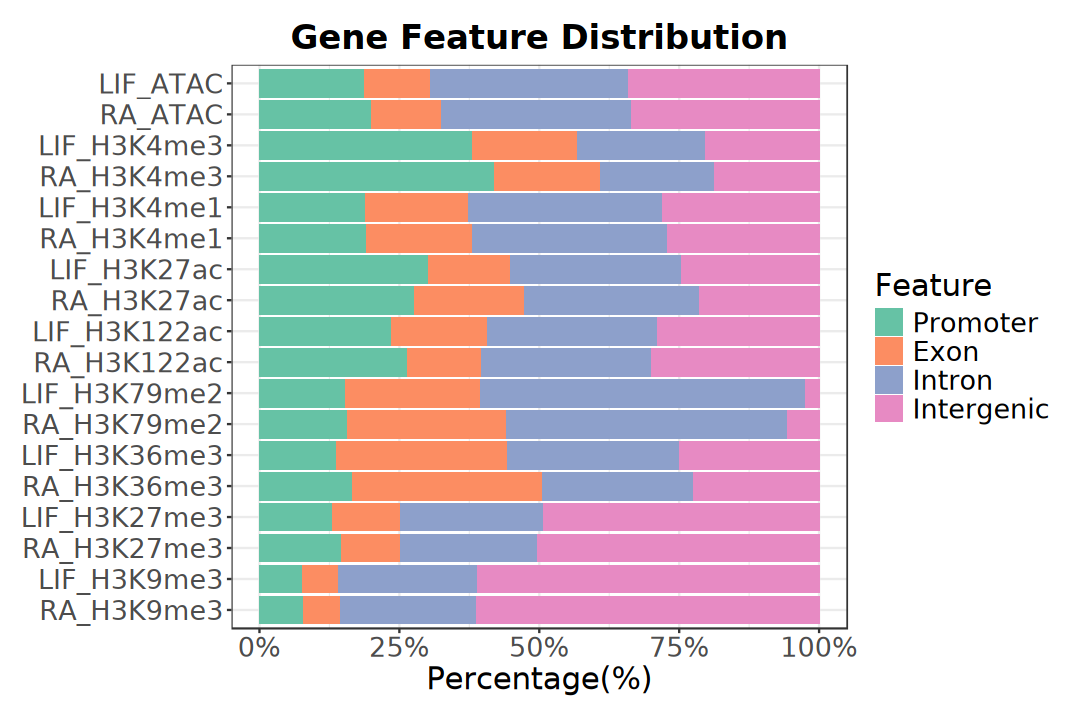

In [34]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_fill(reverse = TRUE)) +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage(%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [35]:
combined_df <- imap_dfr(peaks_anno_list, function(gr, sample_name) {
    df <- as.data.frame(gr)
    df$Sample <- sample_name
    return(df)
})

plot_df <- combined_df |>
    mutate(abs_dist = abs(SignedDistToTSS)) |>
    mutate(Dist_Group = case_when(
        abs_dist <= 1000 ~ "<= 1kb",
        abs_dist > 1000 & abs_dist <= 3000 ~ "1 - 3kb",
        abs_dist > 3000 & abs_dist <= 10000 ~ "3 - 10kb",
        abs_dist > 10000 ~ "> 10kb")) |>
    mutate(Dist_Group = factor(
        Dist_Group, levels = c(
            "<= 1kb", "1 - 3kb", "3 - 10kb", "> 10kb"))) |>
    group_by(Sample, Dist_Group) |>
    tally() |>
    mutate(Percentage = n / sum(n) * 100)

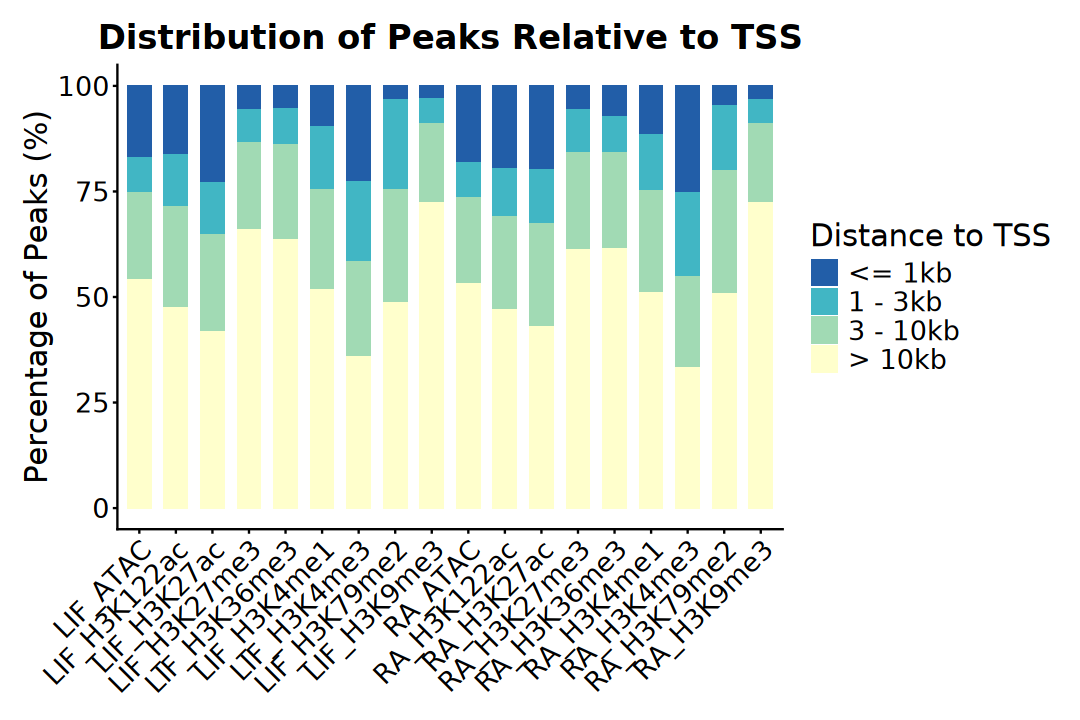

In [36]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = Percentage, fill = Dist_Group)) +
     geom_bar(stat = "identity", position = "stack", width = 0.65) +
     scale_fill_brewer(palette = "YlGnBu", direction = -1) + 
     labs(
          title = "Distribution of Peaks Relative to TSS",
          x = NULL, y = "Percentage of Peaks (%)",
          fill = "Distance to TSS") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 16))

## 3). Metagene Profile (Peaks)

In [37]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

### a). EnrichedHeatmap

In [38]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [39]:
ctrl_index<- grep("LIF", names(peaks_list))
trt_index <- grep("RA", names(peaks_list))

In [40]:
# ~ 5 minutes
peaks_ctrl_gene_mat_list <- lapply(
    peaks_list[ctrl_index], normalizeToMatrix, GENES, 
    mean_mode = "coverage", extend = 2000, w = 50,
    background = 0, target_ratio = 0.4)

In [41]:
# ~ 5 minutes
peaks_trt_gene_mat_list <- lapply(
    peaks_list[trt_index], normalizeToMatrix, GENES, 
    mean_mode = "coverage", extend = 2000, w = 50,
    background = 0, target_ratio = 0.4)

In [42]:
peaks_gene_mat_list <- Map(
    rbind, peaks_ctrl_gene_mat_list, peaks_trt_gene_mat_list)

In [43]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(length(peaks_gene_mat_list)) |> 
    setNames(names(peaks_gene_mat_list))

col_funs <- lapply(names(peaks_gene_mat_list), function(mark) {
    unname(c("#ffffff", base_colors[mark]))
})

names(col_funs) <- names(peaks_gene_mat_list)

In [44]:
line_lgd <- Legend(
    labels = c("LIF", "RA"),
    title = "Treatment",
    legend_gp = gpar(col = c("LIF" = "#e15759", "RA" = "#4e79a7"), lwd = 2),
    type = "lines",
    title_gp = gpar(fontsize = 12, fontface = "bold"),
    labels_gp = gpar(fontsize = 10)
)

packed_lgds <- packLegend(line_lgd)

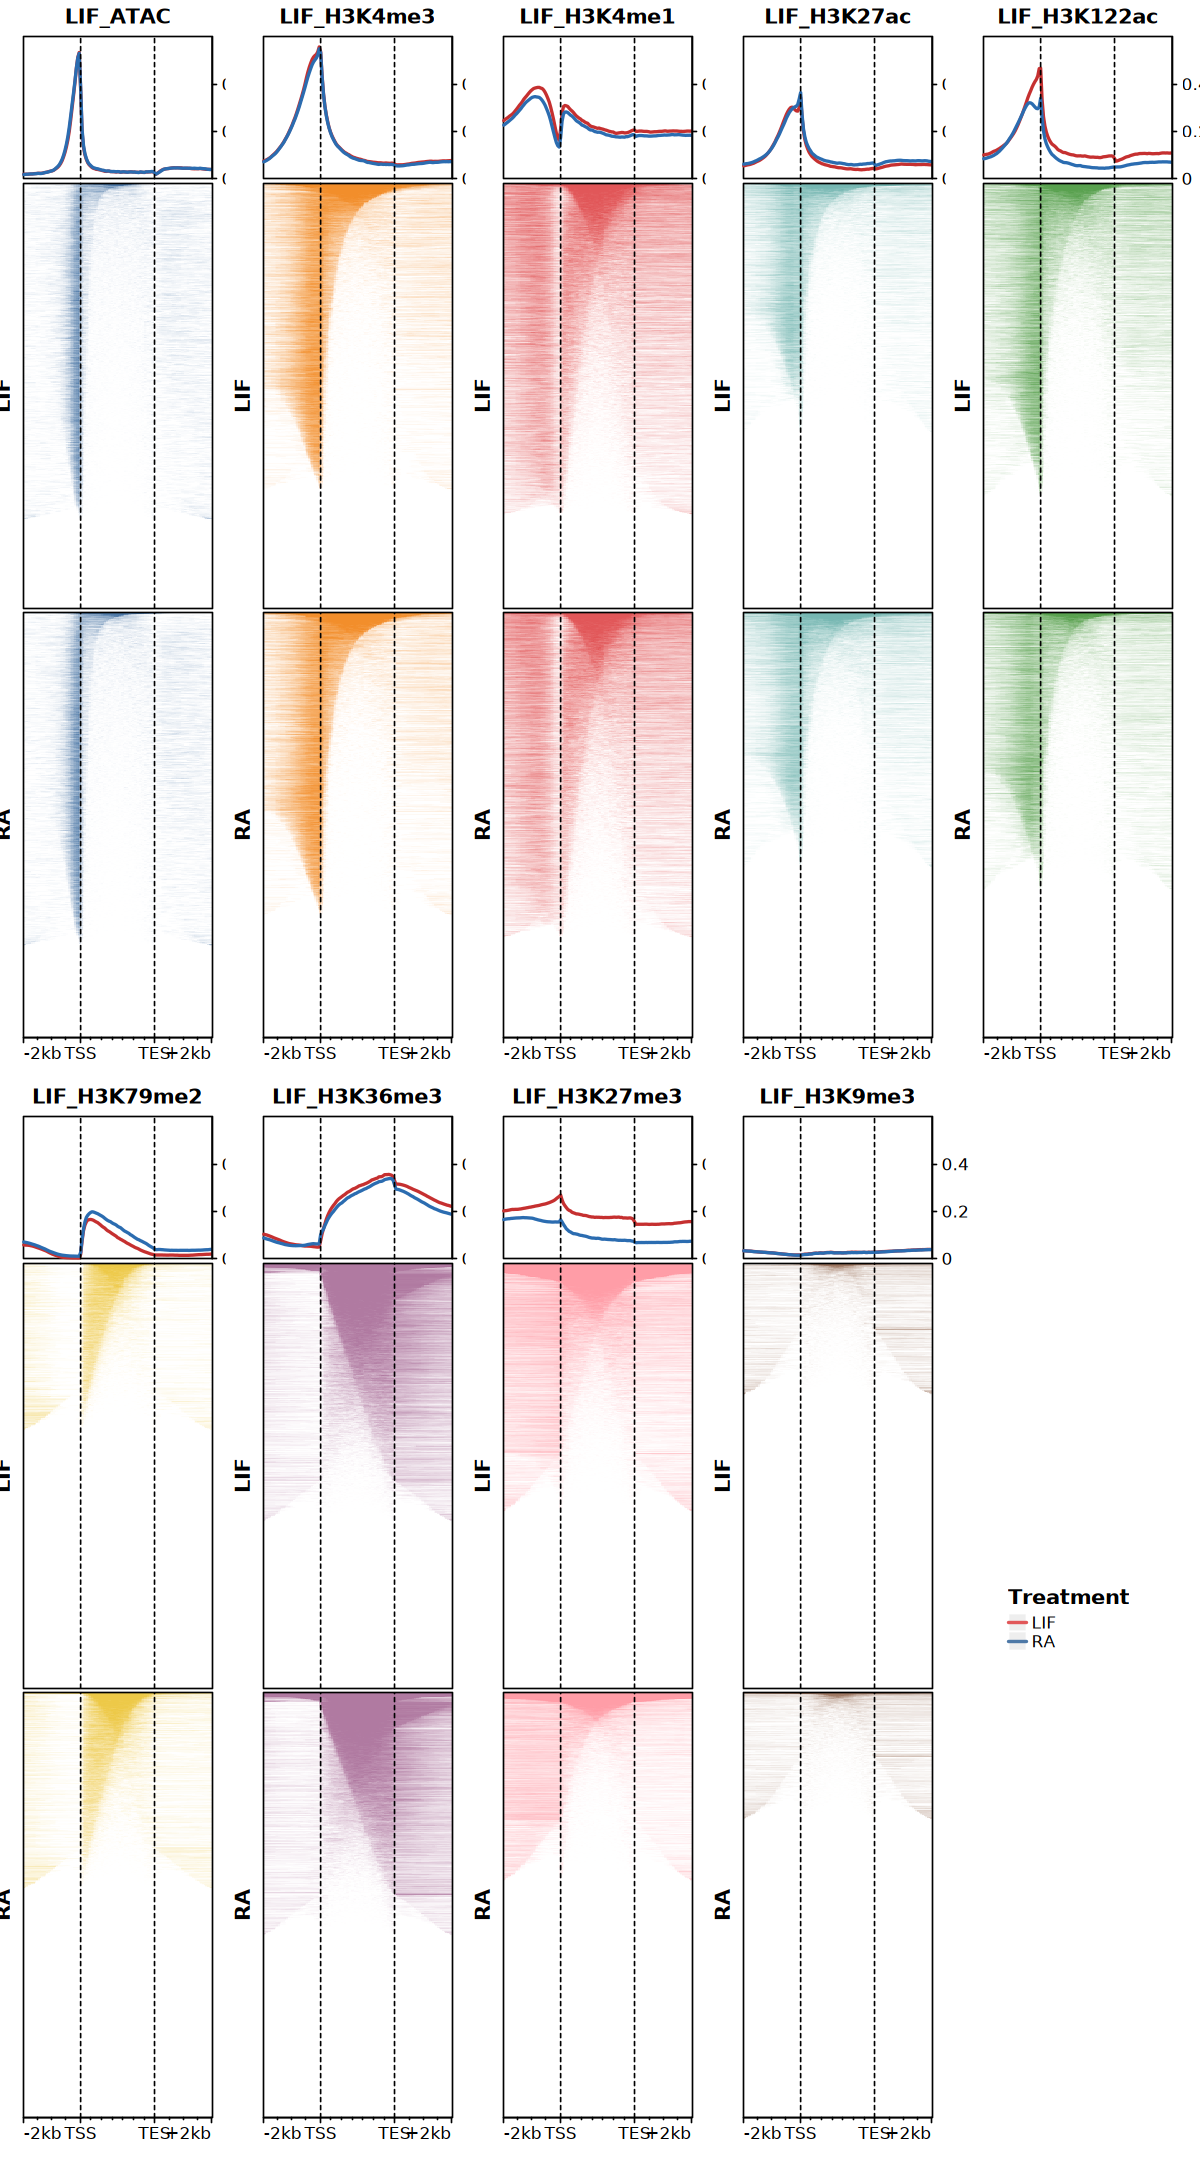

In [45]:
# ==============================================================================
# ⚠️ WARNING / IMPORTANT NOTE:
# With the current settings, the row order (gene/peak order) across different 
# heatmaps is INCONSISTENT. Each heatmap calculates its own hierarchical 
# clustering independently based on its input matrix. If you want to visually 
# compare rows across different groups, you must enforce a unified row order 
# by setting 'cluster_rows = FALSE' and providing a fixed 'row_order'.
# ==============================================================================
options(repr.plot.width = 10, repr.plot.height = 18)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(layout = grid.layout(2, 5)))

for (i in seq_along(peaks_gene_mat_list)) {
    mark_name <- names(peaks_gene_mat_list)[i]

    # Enter the designated grid slot (viewport)
    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))

    n_ctrl <- nrow(peaks_ctrl_gene_mat_list[[i]])
    n_trt <- nrow(peaks_trt_gene_mat_list[[i]])
    group_tags <- c(rep("LIF", n_ctrl), rep("RA", n_trt)) |>
        factor(levels = c("LIF", "RA"))

    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        peaks_gene_mat_list[[i]], 
        name = mark_name,
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"),
        col = col_funs[[mark_name]], 
        row_split = group_tags, 
        row_title_rot = 90, 
        row_title_gp = gpar(fontsize = 12, fontface = "bold"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = c("#C53030", "#2B6CB0")), 
                ylim = c(0, 0.6), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = TRUE), 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 2, layout.pos.col = 5))
draw(
    packed_lgds, x = unit(0.2, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()

In [46]:
position_levels <- c(
    sprintf("u%d", 1:40), 
    sprintf("t%d", 1:53), 
    sprintf("d%d", 1:40)
)

ctrl_df <- purrr::imap_dfr(
    peaks_ctrl_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Coverage = colMeans(.x, na.rm = TRUE)
    )
)

trt_df <- purrr::imap_dfr(
    peaks_trt_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Coverage = colMeans(.x, na.rm = TRUE)
    )
)

profiles_df <- dplyr::bind_rows(ctrl_df, trt_df) |> 
    separate(
        Sample, into = c("Treatment", "Marks"),
        sep = "_", remove = FALSE) |>
    mutate(Marks = factor(Marks, levels = c("ATAC", marks, "Input")))

head(profiles_df)

Position,Sample,Treatment,Marks,Coverage
<fct>,<chr>,<chr>,<fct>,<dbl>
u1,LIF_ATAC,LIF,ATAC,0.01865085
u2,LIF_ATAC,LIF,ATAC,0.01870855
u3,LIF_ATAC,LIF,ATAC,0.01881846
u4,LIF_ATAC,LIF,ATAC,0.01891647
u5,LIF_ATAC,LIF,ATAC,0.01917659
u6,LIF_ATAC,LIF,ATAC,0.01971698


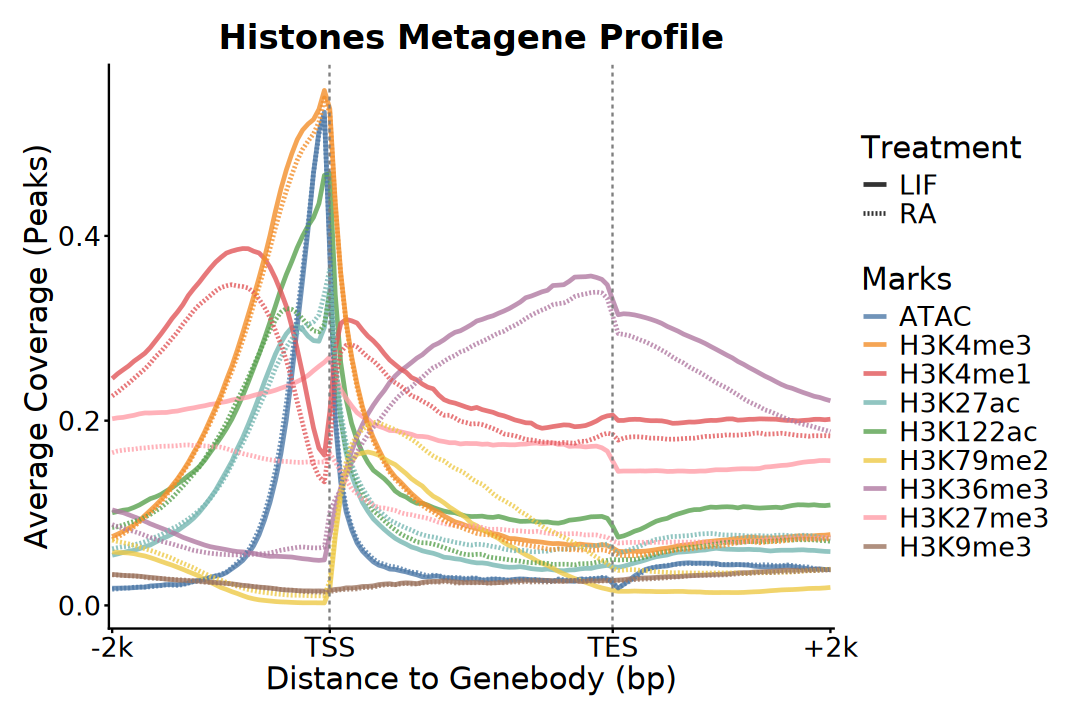

In [47]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Coverage)) +
    geom_line(
        aes(color = Marks, linetype = Treatment, group = Sample), 
        alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), 
        linetype = "dashed", color = "gray50") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) + 
    # scale_color_brewer(palette = "Set1") + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    labs(
        title = "Histones Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Coverage (Peaks)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). Metagene Profile (Signals)

### a). deepTools

In [48]:
atac_matrix_files <- file.path(atacseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

chip_matrix_files <- file.path(chipseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

matrix_files <- c(atac_matrix_files, chip_matrix_files)
names(matrix_files) <- sub("^[^_]+_", "", names(matrix_files))

In [49]:
compute_matrix_mean <- function(file, sample) {
    read.table(file, header = FALSE, sep = "\t", skip = 3) |>
        as.matrix() |> colMeans(na.rm = TRUE)
}

In [50]:
profiles_list <- imap(matrix_files, compute_matrix_mean)

In [51]:
profiles_tss <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    mutate(Position = seq(-2000, 2000, length.out = 400)) |>
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    separate(
        Sample, into = c("Treatment", "Marks"),
        sep = "_", remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("LIF", "RA")),
        Marks = factor(Marks, levels = c("ATAC", marks, "Input")))

head(profiles_tss)

Position,Sample,Treatment,Marks,Signal
<dbl>,<chr>,<fct>,<fct>,<dbl>
-2000,LIF_ATAC,LIF,ATAC,123.1760
-2000,RA_ATAC,RA,ATAC,170.5679
-2000,LIF_H3K122ac,LIF,H3K122ac,237.8598
-2000,LIF_H3K27ac,LIF,H3K27ac,167.9320
-2000,LIF_H3K27me3,LIF,H3K27me3,217.7052
-2000,LIF_H3K36me3,LIF,H3K36me3,175.4827


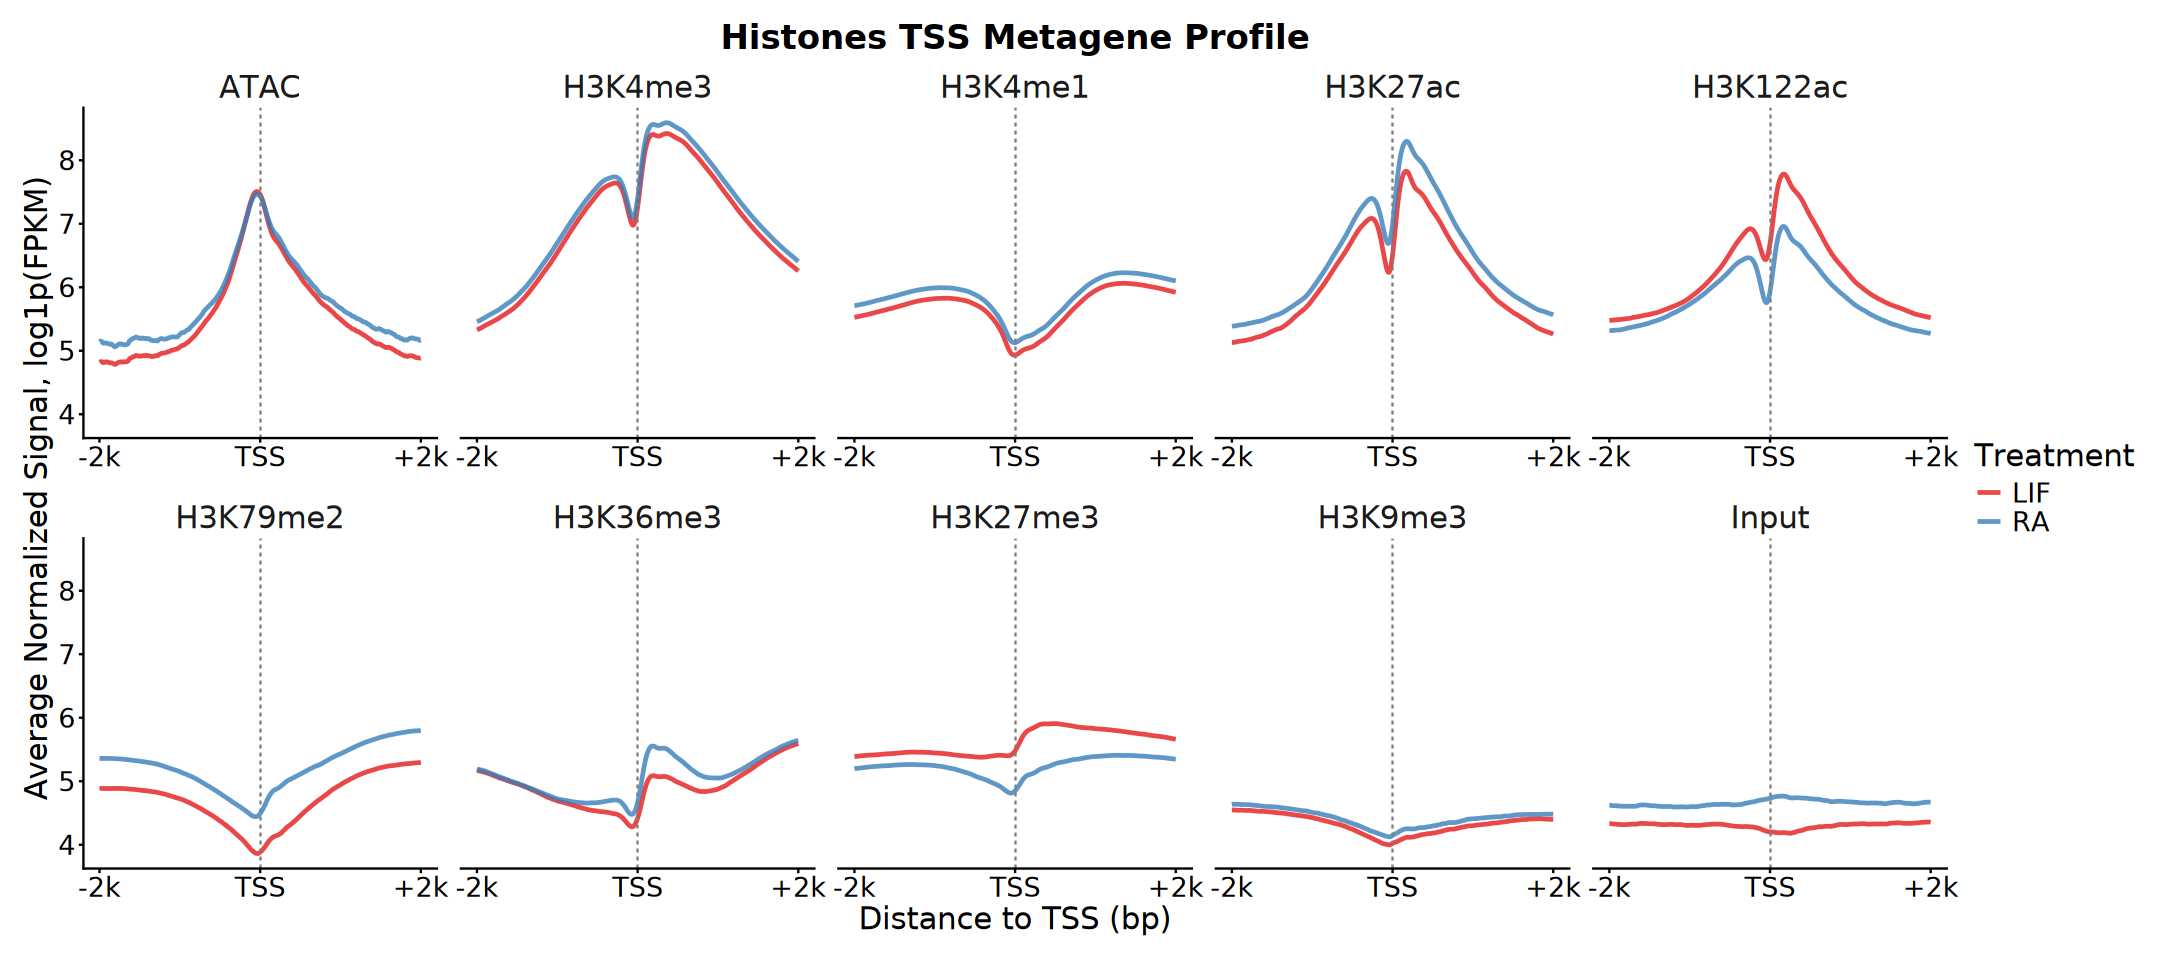

In [52]:
options(repr.plot.width = 18, repr.plot.height = 8)

ggplot(profiles_tss, aes(Position, log1p(Signal))) +
    geom_line(
        aes(color = Treatment), alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        breaks = c(-2000, 0, 2000), labels = c("-2k", "TSS", "+2k")) + 
    scale_color_brewer(palette = "Set1") + 
    facet_wrap(
        ~ Marks, nrow = 2, scales = "free_x", 
        strip.position = "top") +
    labs(
        title = "Histones TSS Metagene Profile", 
        x = "Distance to TSS (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(1, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [53]:
atac_matrix_files <- file.path(atacseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.Genebody\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.Genebody\\.tsv$", "\\1", basename(.x)))

chip_matrix_files <- file.path(chipseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.Genebody\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.Genebody\\.tsv$", "\\1", basename(.x)))

matrix_files <- c(atac_matrix_files, chip_matrix_files)
names(matrix_files) <- sub("^[^_]+_", "", names(matrix_files))

profiles_list <- imap(matrix_files, compute_matrix_mean)

In [54]:
profiles_genebody <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    mutate(Position = seq(-2000, 5000, length.out = 700)) |>
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    separate(
        Sample, into = c("Treatment", "Marks"),
        sep = "_", remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("LIF", "RA")),
        Marks = factor(Marks, levels = c("ATAC", marks, "Input")))

head(profiles_genebody)

Position,Sample,Treatment,Marks,Signal
<dbl>,<chr>,<fct>,<fct>,<dbl>
-2000,LIF_ATAC,LIF,ATAC,123.1760
-2000,RA_ATAC,RA,ATAC,170.5679
-2000,LIF_H3K122ac,LIF,H3K122ac,237.8598
-2000,LIF_H3K27ac,LIF,H3K27ac,167.9320
-2000,LIF_H3K27me3,LIF,H3K27me3,217.7052
-2000,LIF_H3K36me3,LIF,H3K36me3,175.4827


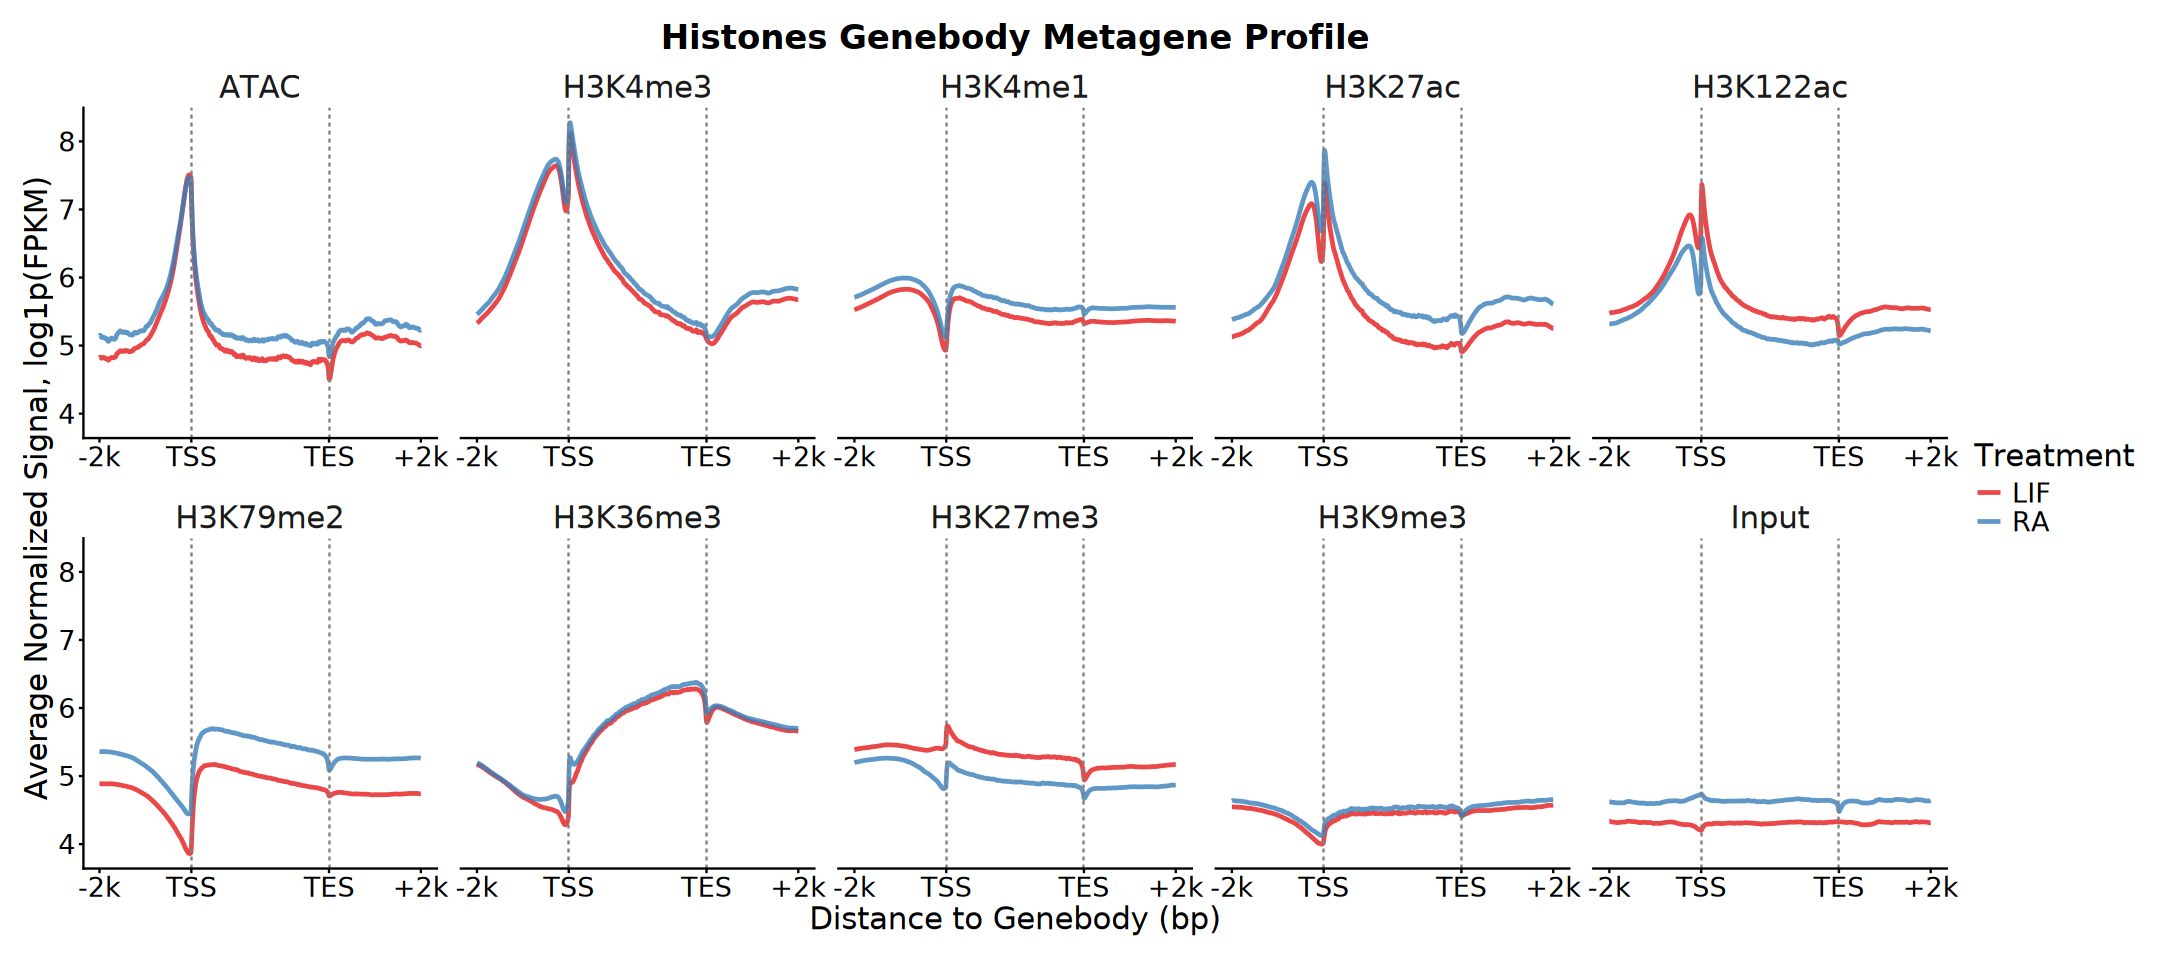

In [55]:
options(repr.plot.width = 18, repr.plot.height = 8)

ggplot(profiles_genebody, aes(Position, log1p(Signal))) +
    geom_line(
        aes(color = Treatment), alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c(0, 3000), linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        breaks = c(-2000, 0, 3000, 5000), 
        labels = c("-2k", "TSS", "TES", "+2k")) + 
    scale_color_brewer(palette = "Set1") + 
    facet_wrap(
        ~ Marks, nrow = 2, scales = "free_x", 
        strip.position = "top") +
    labs(
        title = "Histones Genebody Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(1, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). EnrichedHeatmap

In [56]:
ctrl_index<- grep("LIF", names(signals_list))
trt_index <- grep("RA", names(signals_list))

In [57]:
# ~ 15 minutes
signals_ctrl_gene_mat_list <- lapply(
    signals_list[ctrl_index], normalizeToMatrix, GENES, 
    value_column = "score", mean_mode = "w0", 
    extend = 2000, w = 50, smooth = TRUE, 
    background = 0, target_ratio = 0.4)

In [58]:
# ~ 15 minutes
signals_trt_gene_mat_list <- lapply(
    signals_list[trt_index], normalizeToMatrix, GENES, 
    value_column = "score", mean_mode = "w0", 
    extend = 2000, w = 50, smooth = TRUE, 
    background = 0, target_ratio = 0.4)

In [59]:
signals_gene_mat_list <- Map(
    rbind, signals_ctrl_gene_mat_list, signals_trt_gene_mat_list)

In [60]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_gene_mat_list)) |> 
    setNames(names(signals_gene_mat_list))

col_funs <- lapply(names(signals_gene_mat_list), function(mark) {
    max_val <- abs(signals_gene_mat_list[[mark]]) |>
        quantile(0.95, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, max_val/2, max_val), 
        c("#ffffff", base_colors[mark], "#03045e"))
})

names(col_funs) <- names(signals_gene_mat_list)

In [61]:
lgd_list <- lapply(names(col_funs), function(mark) {
    Legend(
        col_fun = col_funs[[mark]], title = mark, 
        title_gp = gpar(fontsize = 12, fontface = "bold"),
        labels_gp = gpar(fontsize = 10), grid_width = unit(0.4, "cm"))
})

line_lgd <- Legend(
    labels = c("LIF", "RA"),
    title = "Treatment",
    legend_gp = gpar(col = c("LIF" = "#e15759", "RA" = "#4e79a7"), lwd = 2),
    type = "lines",
    title_gp = gpar(fontsize = 12, fontface = "bold"),
    labels_gp = gpar(fontsize = 10)
)

lgd_col1 <- packLegend(list = lgd_list[1:5], direction = "vertical")
lgd_col2 <- packLegend(list = lgd_list[6:10], direction = "vertical")
packed_lgds <- packLegend(
    lgd_col1, lgd_col2, direction = "horizontal", gap = unit(0.8, "cm")) |>
    packLegend(line_lgd, direction = "vertical", gap = unit(0.8, "cm"))

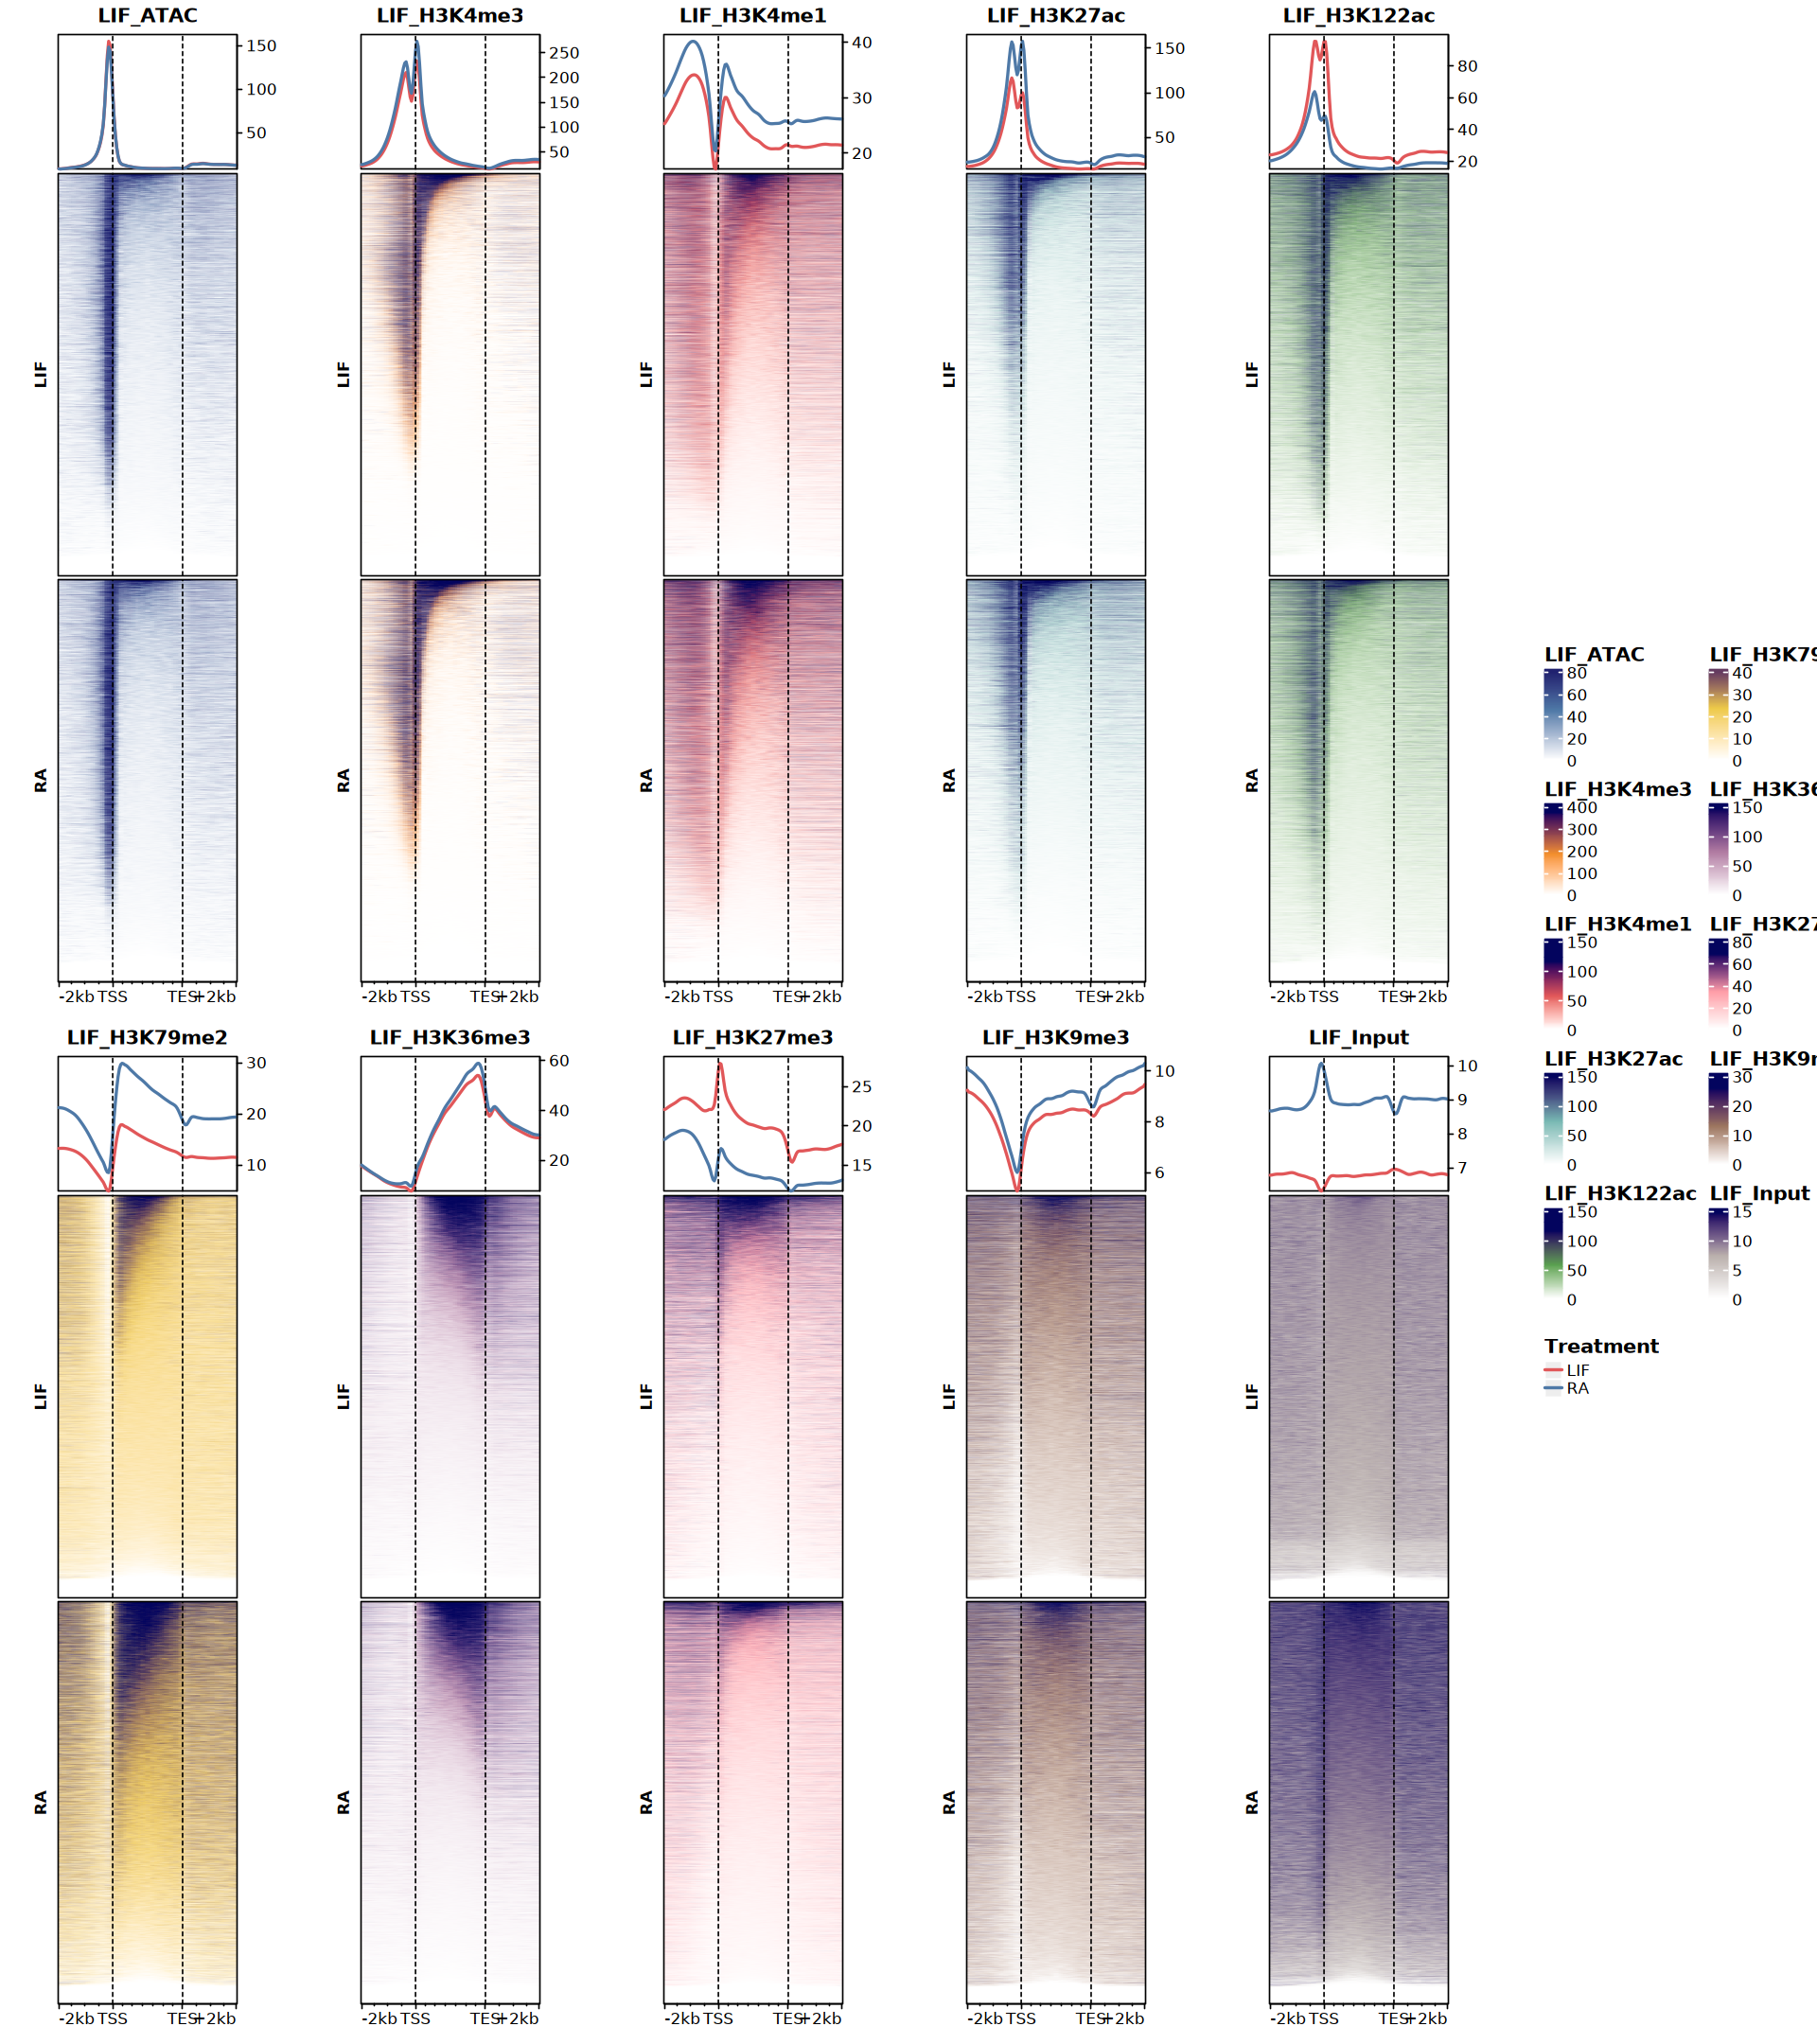

In [62]:
# ==============================================================================
# ⚠️ WARNING / IMPORTANT NOTE:
# With the current settings, the row order (gene/peak order) across different 
# heatmaps is INCONSISTENT. Each heatmap calculates its own hierarchical 
# clustering independently based on its input matrix. If you want to visually 
# compare rows across different groups, you must enforce a unified row order 
# by setting 'cluster_rows = FALSE' and providing a fixed 'row_order'.
# ==============================================================================

options(repr.plot.width = 16, repr.plot.height = 18)

# Create a new blank canvas
grid.newpage()
pushViewport(viewport(layout = grid.layout(2, 6)))

for (i in seq_along(signals_gene_mat_list)) {
    mark_name <- names(signals_gene_mat_list)[i]

    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))

    n_ctrl <- nrow(signals_ctrl_gene_mat_list[[i]])
    n_trt <- nrow(signals_trt_gene_mat_list[[i]])
    group_tags <- c(rep("LIF", n_ctrl), rep("RA", n_trt)) |>
        factor(levels = c("LIF", "RA"))

    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        signals_gene_mat_list[[i]], 
        name = mark_name, 
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"),
        col = col_funs[[mark_name]], 
        row_split = group_tags, 
        row_title_rot = 90, 
        row_title_gp = gpar(fontsize = 10, fontface = "bold"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = c("#e15759", "#4e79a7")), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = TRUE), 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 6))
draw(
    packed_lgds, x = unit(0.1, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()

In [63]:
position_levels <- c(
    sprintf("u%d", 1:40), 
    sprintf("t%d", 1:53), 
    sprintf("d%d", 1:40)
)

ctrl_df <- purrr::imap_dfr(
    signals_ctrl_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Signal = colMeans(.x, na.rm = TRUE)
    )
)

trt_df <- purrr::imap_dfr(
    signals_trt_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Signal = colMeans(.x, na.rm = TRUE)
    )
)

profiles_df <- dplyr::bind_rows(ctrl_df, trt_df) |> 
    separate(
        Sample, into = c("Treatment", "Marks"),
        sep = "_", remove = FALSE) |>
    mutate(Marks = factor(Marks, levels = c("ATAC", marks, "Input")))

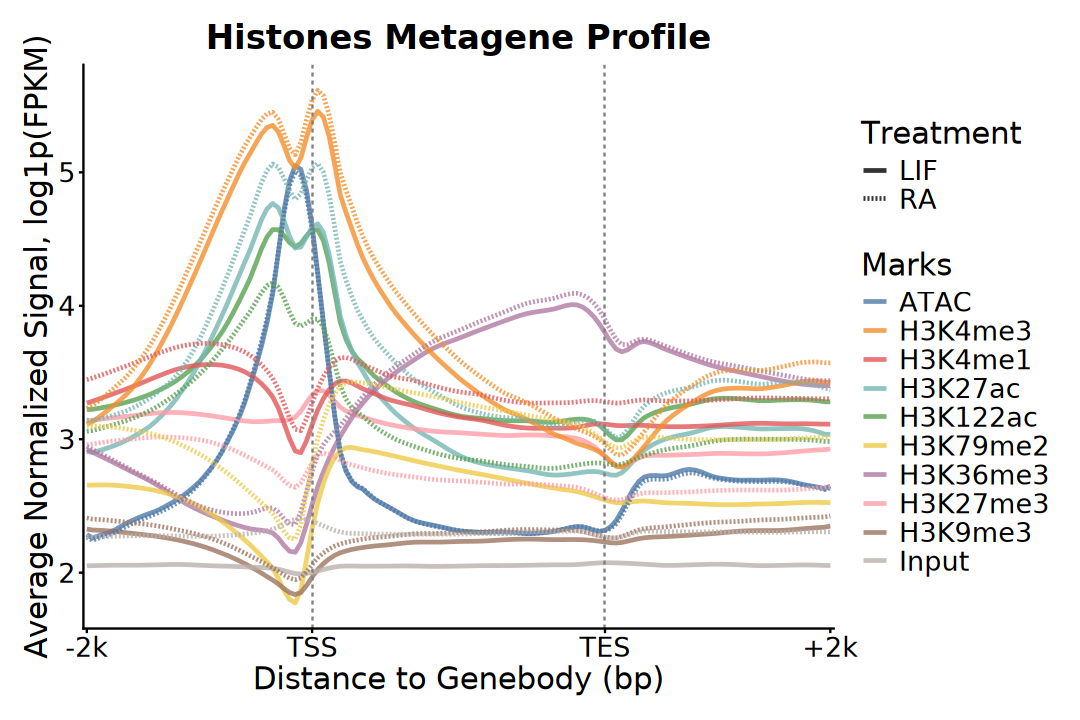

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, log1p(Signal))) +
    geom_line(
        aes(color = Marks, linetype = Treatment, group = Sample), 
        alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), 
        linetype = "dashed", color = "gray50") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) + 
    # scale_color_brewer(palette = "Set1") + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    labs(
        title = "Histones Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

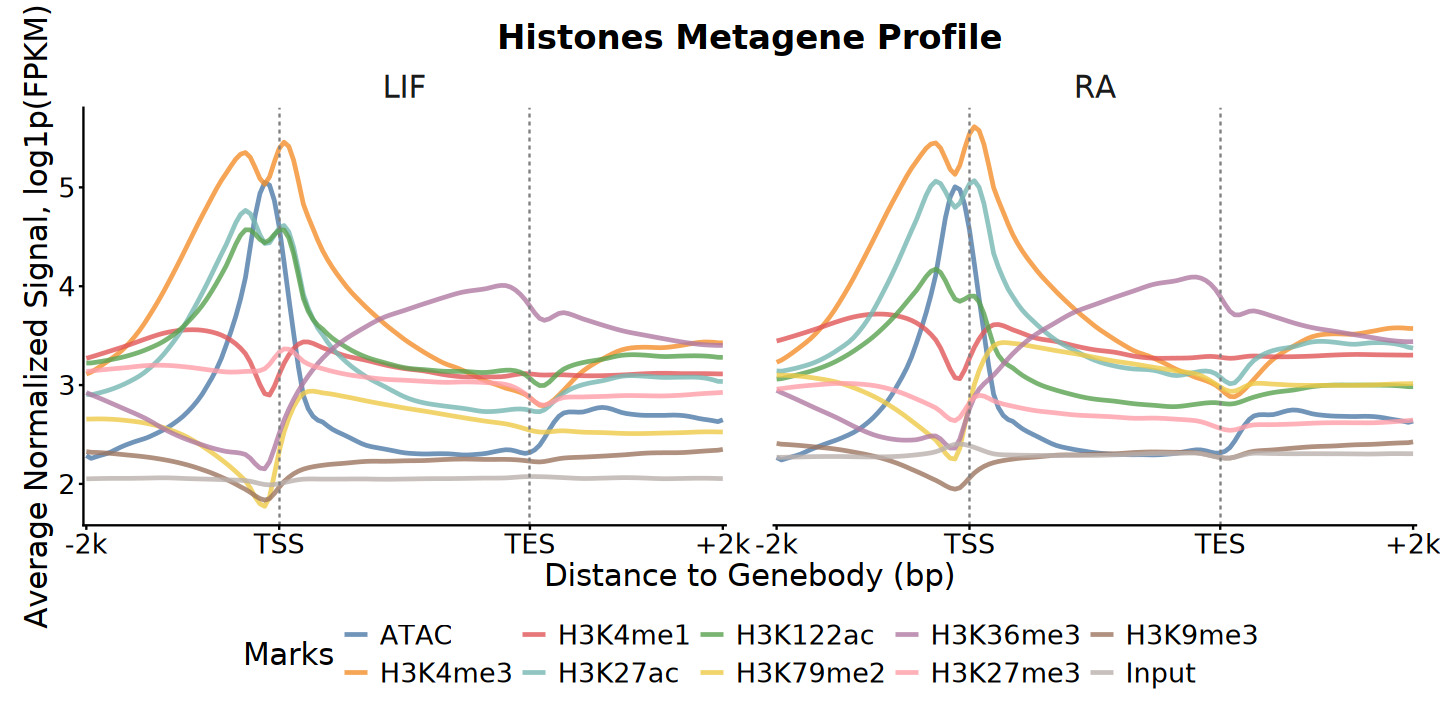

In [65]:
options(repr.plot.width = 12, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, log1p(Signal))) +
    geom_line(
        aes(color = Marks, group = Marks), 
        alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), 
        linetype = "dashed", color = "gray50") +
    facet_wrap(~ Treatment, ncol = 2) + 
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) + 
    # scale_color_brewer(palette = "Set1") + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    labs(
        title = "Histones Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(2, "lines"), 
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        strip.placement = "outside",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). IGV snapshot

In [66]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [67]:
# Hoxa
genome = "mm10"
target_region <- "chr6:52150000-52230000"

In [68]:
target_region <- str_match(target_region, "([^:]+):(\\d+)-(\\d+)") |> 
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), 
        end = as.numeric(V4)) |>
    column_to_rownames("pos")
target_region

,chr,start,end
,<chr>,<dbl>,<dbl>
chr6:52150000-52230000,chr6,52150000,52230000


In [69]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53180
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm10
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm10
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm10/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53180"]]' 

In [70]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(
        chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [71]:
idTrack <- IdeogramTrack(
    chromosome = target_region$chr, genome = genome, 
    name = str_to_title(target_region$chr), bands = bands,
    fontcolor = "black", fontsize = 20)
scale_bar <- GenomeAxisTrack(
    scale = 0.1, col = "black", fontcolor = "black", 
    labelPos = "above", showTitle = FALSE, fontsize = 16,
    distFromAxis = 1, lwd = 1)
coordinate <- GenomeAxisTrack(
    labelPos = "above", col = "black", fontcolor = "black", 
    exponent = 0, showTitle = FALSE, fontsize = 14, lwd = 2)

plot_list <- list(idTrack, scale_bar, coordinate)

In [72]:
pattern <- "ATAC|H3K4me3|H3K27me3"
index <- grep(pattern, names(signals_list))

tableau_colors <- ggthemes::tableau_color_pal(palette = "Tableau 10")(10)
colors_palette <- colorRampPalette(tableau_colors)(length(signals_list[index]))
names(colors_palette) <- names(signals_list[index])

In [73]:
signal_tracks <- purrr::imap(
    signals_list[index], ~ Gviz::DataTrack(
        range = .x, name = .y, type = "histogram",
        chromosome = target_region$chr, genome = genome,
        showTitle = TRUE, fontsize = 12, cex.title = 1, cex.axis = 0.8,
        col.title = "black", fontcolor.title = "black",
        col.histogram = colors_palette[.y],
        fill.histogram = colors_palette[.y]
    )
)

In [74]:
grtrack <- GeneRegionTrack(
    txdb, genome = genome, chromosome = target_region$chr, 
    start = target_region$start, end = target_region$end,
    transcriptAnnotation = "symbol", showId = TRUE, geneSymbol = TRUE, 
    collapseTranscripts = "longest", fontsize = 20, 
    cex.title = 1, fontsize.group = 16, rotation.title = 0,
    name = "Gene", col = "grey", fill = "orange", 
    fontcolor.group = "black", stacking = "squish")

gene_info <- filter(gtf, type == "gene")

ranges(grtrack)$symbol <- gene_info$gene_name[
    match(ranges(grtrack)$gene, gene_info$gene_id)]

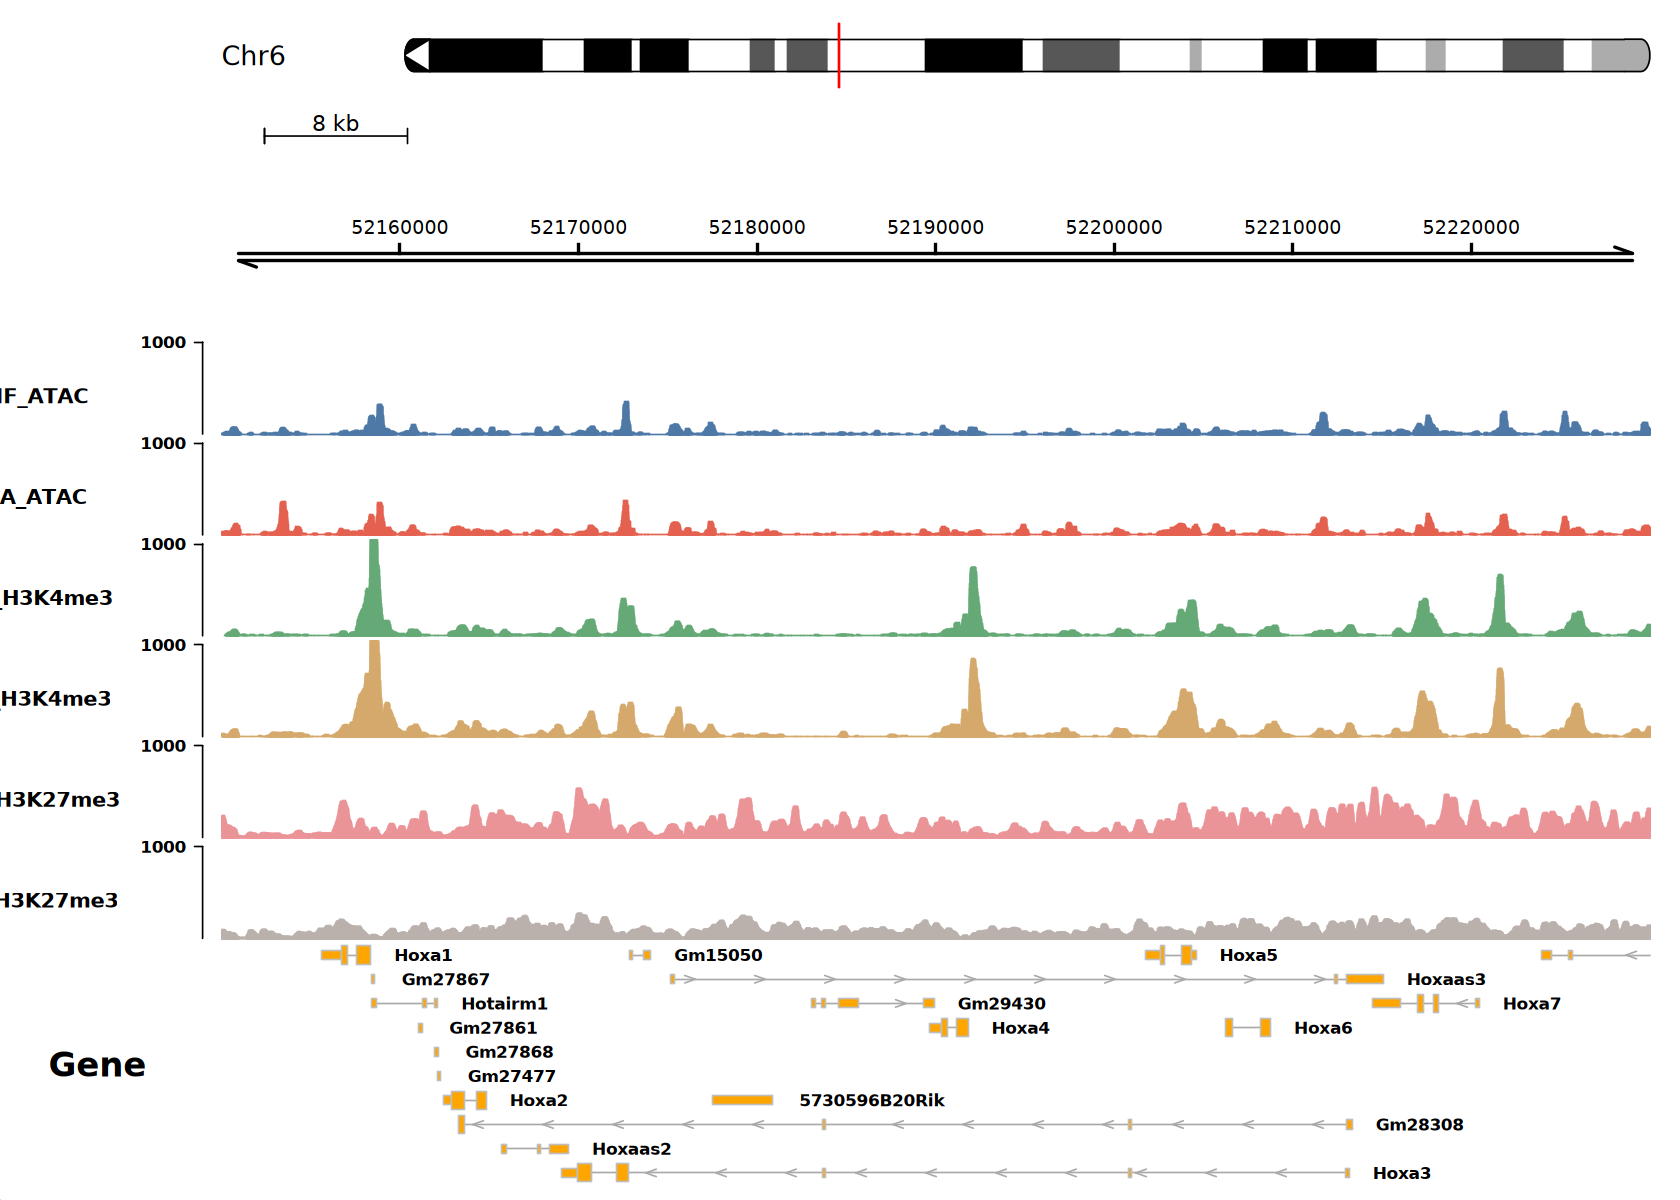

In [75]:
options(repr.plot.width = 14, repr.plot.height = 10)

plotTracks(
    trackList = c(plot_list, signal_tracks, grtrack), 
    chromosome = target_region$chr, from = target_region$start, to = target_region$end, 
    background.title = "white", col.title = "black", col.axis = "black", 
    sizes = c(2, 2, 4, rep(2.5, length(signals_list[index])), 6), 
    reverseStrand = FALSE, rotation.title = 0, title.width = 1, 
    just.group = "right", extend.left = 0, 
    ylim = c(0, 1000), yTicksAt = c(1000))